<center>
  <h3>More than a Hack 2027 &middot; Phase 1</h3>
  <h2>Frame-level Ball Possession &mdash; 001 Baseline</h2>

  <p><strong>Metrica Sports &times; FC Barcelona Innovation Hub &times; Mobile World Capital</strong></p>
</center>

---

### Three Makasih

- **Anggota 1** (<span style="color:gray">email</span>)
- **Anggota 2** (<span style="color:gray">email</span>)
- **Anggota 3** (<span style="color:gray">email</span>)

---

## Ringkasan

Baseline resmi: pemain terdekat ke bola dianggap menguasai bola, `D` bila bola tidak terlihat, lalu **majority vote** pada jendela ±*w* frame. Empat varian hanya berbeda pada *w* ∈ {0, 25, 50, 125}.

Tujuan eksperimen ini adalah mereproduksi lantai yang dipublikasikan (`baseline_smooth50`, spellF1 0,2433 pada pertandingan penuh) dan memahami mengapa `macroF1` dan `spellF1` tidak sepakat.


# Metodologi

**Tracking ATD → pemain terdekat ke bola (meter) → kode tim per frame → majority vote jendela ±*w* → `out/*.csv` → validasi → skor pada GT publik.**

# Environment

Dijalankan dari dalam repositori. Parsing ATD memakan sekitar satu menit pada run pertama, lalu di-cache.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").exists())
for p in (ROOT, ROOT / "starter", ROOT / "evaluation", ROOT / "experiments"):
    sys.path.insert(0, str(p))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import common
from games import asset_paths, half_video_blocks, source_frames

FPS = 25
N_FRAMES = source_frames("tactical")
BLOCKS = half_video_blocks("BAR-ATH")   # [(half, first, last)] -> frame yang dinilai
GRADED = np.zeros(N_FRAMES, bool)
for _, a, b in BLOCKS:
    GRADED[a:b + 1] = True
COLORS = {"H": "#A50044", "A": "#C8102E", "D": "#7F7F7F", "X": "#DDDDDD"}
print("ROOT:", ROOT, "| frames:", N_FRAMES, "| graded:", GRADED.sum())

ROOT: /home/ryz/data/dev/competitive/hackathon/More Than hack/more-than-a-hack-2027 | frames: 199319 | graded: 158857


# Approach: Nearest Player + Majority Vote

## [1] Kode tim per frame

Koordinat ATD ternormalisasi 0–1 dan lapangan tidak persegi, sehingga kedua sumbu dikonversi ke meter sebelum jarak dibandingkan.

In [2]:
from baseline import build, smooth, write_submission
codes = common.cached("atd_nearest", build)       # 0=H, 1=A, -1=tanpa bola
print(pd.Series(codes[GRADED]).map({0: "H", 1: "A", -1: "tanpa bola"}).value_counts().to_string())

tanpa bola    64643
H             53147
A             41067


## [2] Smoothing dengan jendela berbeda

Tanpa smoothing label berkedip antar frame, sehingga jumlah possession meledak.

In [3]:
OUT = Path(common.HERE) / "001_baseline" / "out"
variants = {"smooth%d" % w: smooth(codes, w) for w in (0, 25, 50, 125)}
for name, labels in variants.items():
    write_submission(str(OUT / (name + ".csv")), labels)
print(sorted(p.name for p in OUT.glob("*.csv")))

['smooth0.csv', 'smooth125.csv', 'smooth25.csv', 'smooth50.csv']


## [3] Skor pada GT publik

Hanya **pemeriksaan pipeline**. Angka di bawah memakai 17 possession, jadi selisih kecil tidak bermakna.

In [4]:
import io, contextlib, subprocess
res = subprocess.run([sys.executable, str(ROOT / "evaluation" / "run_evaluation.py"),
                      "--results", str(OUT), "--out", str(OUT / "reports")],
                     capture_output=True, text=True)
board = pd.read_csv(OUT / "reports" / "scoreboard.csv")
display(board)

,rank,submission,status,reason,macro_f1,spell_f1_mean,poss,dur,n_gt_spells,gt_mean_spell_duration_s,...,n_pred_segments,fragmentation,n_graded,n_abstain_on_graded,trans_f1_12,trans_precision_12,trans_recall_12,trans_f1_25,trans_precision_25,trans_recall_25
0,1,smooth125,scored,NaN,0.581185,0.424242,16,18.460000,17,14.190588,...,17,0.809524,7500,0,0.111111,0.125000,0.10,0.166667,0.187500,0.15
1,2,smooth50,scored,NaN,0.620733,0.325581,26,10.803077,17,14.190588,...,30,1.428571,7500,0,0.081633,0.068966,0.10,0.081633,0.068966,0.10
2,3,smooth25,scored,NaN,0.619991,0.286792,36,7.580000,17,14.190588,...,40,1.904762,7500,0,0.169492,0.128205,0.25,0.203390,0.153846,0.30
3,4,smooth0,scored,NaN,0.597227,0.037838,131,2.019847,17,14.190588,...,137,6.523810,7500,0,0.064103,0.036765,0.25,0.141026,0.080882,0.55


## [4] Publik vs pertandingan penuh

Skor pertandingan penuh berikut dikutip dari `EVALUATION.md` (bukan dihitung ulang di sini karena GT penuh bersifat privat).

,varian,macroF1_full,spellF1_full
0,raw,0.6532,0.0486
1,smooth25,0.6752,0.1996
2,smooth50,0.6724,0.2433
3,smooth125,0.6356,0.2242


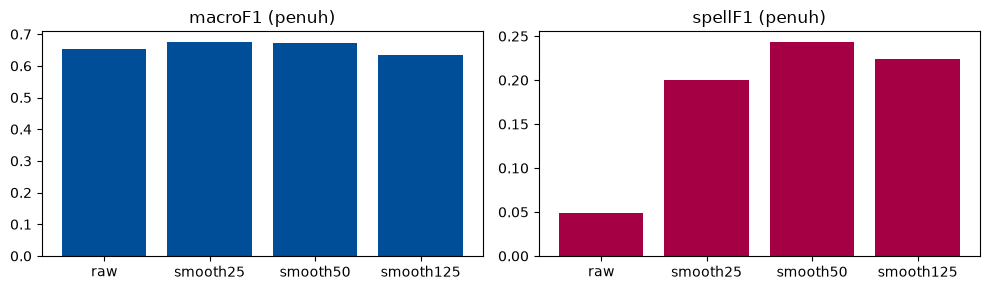

In [5]:
full = pd.DataFrame({"varian": ["raw", "smooth25", "smooth50", "smooth125"],
                     "macroF1_full": [0.6532, 0.6752, 0.6724, 0.6356],
                     "spellF1_full": [0.0486, 0.1996, 0.2433, 0.2242]})
display(full)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].bar(full.varian, full.macroF1_full, color="#004D98"); ax[0].set_title("macroF1 (penuh)")
ax[1].bar(full.varian, full.spellF1_full, color="#A50044"); ax[1].set_title("spellF1 (penuh)")
plt.tight_layout(); plt.show()

`macroF1` bergerak ±0,04 dan memilih `smooth25`, sedangkan `spellF1` bergerak lima kali lipat dan memilih `smooth50`. Pada GT publik justru `smooth125` terbaik; memilih jendela dari 5 menit publik akan salah.

## [5] Output

Submission baseline berada di `experiments/001_baseline/out/`. Eksperimen berikutnya harus mengalahkan `spellF1` 0,2433 pada pertandingan penuh tanpa tuning pada GT publik.